<a href="https://colab.research.google.com/github/lagavenkateswarlu/Vehicle-Price-Prediction/blob/main/VECHICLE_PRICE_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#****VECHILE PRICE PREDICTION ML PROJECT****

####**OUR ALOGIRTHM WILL TAKE VECHILE DETAILS LIKE MILEAGE, ENGINE TYPE, NO OF DOORS, LENGTH, WIDTH, HEIGHT, ENGINE CAPACITY, ETC  AND  OUR  ALGORITHM WILL PRIDICT PRICE OF THE VECHILE.**

#****IMPORT ALL LIBRARIES****

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [30]:
from google.colab import files
uploaded = files.upload()

Saving auto.txt to auto (1).txt


#****STEP.1 - LOAD THE DATA****

In [31]:
df=pd.read_csv('auto.txt')

# ****STEP.2 - CLEAN THE DATA****

In [32]:
df.shape #IT SHOWS THAT ROW AND COLUMN COUNT

(205, 26)

In [33]:
df.head() # IT SHOWS FIRST FIVE ROWS DATA

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [34]:
df.tail() # IT SHOWS LAST FIVE ROWS

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470
204,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625


In [35]:
df.info()#check data information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

In [36]:
#I CONVERTED TO OBJECT TO NUMERIC VALUES
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')
df['bore']=pd.to_numeric(df['bore'],errors='coerce')
df['stroke']=pd.to_numeric(df['stroke'],errors='coerce')
df['peak-rpm']=pd.to_numeric(df['peak-rpm'],errors='coerce')
df['num-of-doors'] = df['num-of-doors'].replace('?', np.nan)

df['num-of-doors'] = pd.to_numeric(df['num-of-doors'], errors='coerce')

df['num-of-doors'].fillna(df['num-of-doors'].mean(), inplace=True)


/tmp/ipykernel_5209/4192041253.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['num-of-doors'].fillna(df['num-of-doors'].mean(), inplace=True)


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       0 non-null      float64
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

###**LET USE REMOVE UNWANTED COLUMNS -- WHICH ARE NOT USEFULL**

In [38]:
del df['normalized-losses'] # I HAS DELETE THIS COLUMNS


In [39]:
df.columns

Index(['symboling', 'make', 'fuel-type', 'aspiration', 'num-of-doors',
       'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length',
       'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders',
       'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio',
       'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

In [40]:
# BY USING DICTIONARY MAPPING I CONVERTED STRING TO NUMBER
cylinders_dict = {
    'two': 2, 'three': 3, 'four': 4, 'five': 5,
    'six': 6, 'eight': 8, 'twelve': 12
}

fuel_system = {
    '1bbl': 1, '2bbl': 2, '4bbl': 4, 'idi': 5,
    'mfi': 6, 'mpfi': 7, 'spdi': 8, 'spfi': 9
}

fuel_type = {
    'gas': 1,
    'diesel': 2
}

engine_type = {
    'dohc': 1, 'dohcv': 2, 'l': 3, 'ohc': 4,
    'ohcf': 5, 'ohcv': 6, 'rotor': 7
}

engine_location = {'front': 1, 'rear': 2}

drive_wheels = {'4wd': 1, 'fwd': 2, 'rwd': 3}

make = {
    'alfa-romero': 1, 'audi': 2, 'bmw': 3, 'chevrolet': 4,
    'dodge': 5, 'honda': 6, 'isuzu': 7, 'jaguar': 8,
    'mazda': 9, 'mercedes-benz': 10, 'mercury': 11,
    'mitsubishi': 12, 'nissan': 13, 'peugot': 14,
    'plymouth': 15, 'porsche': 16, 'renault': 17,
    'saab': 18, 'subaru': 19, 'toyota': 20,
    'volkswagen': 21, 'volvo': 22
}

body_style = {
    'convertible': 1, 'hardtop': 2,
    'hatchback': 3, 'sedan': 4, 'wagon': 5
}

num_of_doors = {
    'four': 4,
    'two': 2
}

aspiration = {
    'std': 0,
    'turbo': 1
}

# REPLACING STRING VALUES WITH NUMBERS

df['num-of-cylinders'] = df['num-of-cylinders'].replace(cylinders_dict)

df['fuel-system'] = df['fuel-system'].replace(fuel_system)

df['fuel-type'] = df['fuel-type'].replace(fuel_type)

df['engine-type'] = df['engine-type'].replace(engine_type)

df['engine-location'] = df['engine-location'].replace(engine_location)

df['drive-wheels'] = df['drive-wheels'].replace(drive_wheels)

df['make'] = df['make'].replace(make)

df['body-style'] = df['body-style'].replace(body_style)

df['num-of-doors'] = df['num-of-doors'].replace(num_of_doors)

df['aspiration'] = df['aspiration'].replace(aspiration)

df.head()

/tmp/ipykernel_5209/4009736534.py:53: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['num-of-cylinders'] = df['num-of-cylinders'].replace(cylinders_dict)
/tmp/ipykernel_5209/4009736534.py:55: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['fuel-system'] = df['fuel-system'].replace(fuel_system)
/tmp/ipykernel_5209/4009736534.py:57: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to th

,symboling,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,1,1,0,NaN,1,3,1,88.6,168.8,...,130,7,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,1,1,0,NaN,1,3,1,88.6,168.8,...,130,7,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,1,1,0,NaN,3,3,1,94.5,171.2,...,152,7,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,2,1,0,NaN,4,2,1,99.8,176.6,...,109,7,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,2,1,0,NaN,4,1,1,99.4,176.6,...,136,7,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [41]:
df.columns

Index(['symboling', 'make', 'fuel-type', 'aspiration', 'num-of-doors',
       'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length',
       'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders',
       'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio',
       'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

In [42]:
df.isna().sum() # IT CHECKS IF ANY CELLS CONTAINING NULL VALUES OR NOT

,0
symboling,0
make,0
fuel-type,0
aspiration,0
num-of-doors,205
body-style,0
drive-wheels,0
engine-location,0
wheel-base,0
length,0


In [43]:
df.isnull().values.any() # IT CHECKS IF ANY CELLS CONTAINING NULL VALUES OR NOT

np.True_

In [44]:
#clean the data
del df['horsepower']
del df ['num-of-doors']
del df ['curb-weight']
del df ['peak-rpm']

In [45]:
#LETS CLEAN UP OUR DATA
df=df.dropna()

# ****STEP.3 - TRAIN TEST SPLIT THE DATA****

In [46]:
from sklearn.model_selection import train_test_split

# lets feed our data to machine learning model

x = df.drop('price', axis=1)

y = df['price']

# split data into 80% for training, 20% for testing

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=0
)

x_train.shape

(157, 20)

In [47]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(157, 20)
(40, 20)
(157,)
(40,)


# ****STEP.4 - TRAIN THE ALGORITHM****

In [48]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(x_train, y_train)



LinearRegression()

In [49]:
linear_model.score(x_train,y_train)

0.9050760326007832

In [50]:
predictors = x_train.columns

# see the weights associated with particular feature

coef = pd.Series(linear_model.coef_,predictors).sort_values()

print(coef)

bore                 -6166.197859
fuel-type            -5124.620674
stroke               -4841.534780
num-of-cylinders     -1382.661734
body-style            -849.235237
symboling             -569.470354
make                  -191.771029
engine-type           -114.075103
city-mpg               -80.609401
wheel-base             -73.026840
length                  78.366512
highway-mpg            126.966000
engine-size            177.941261
fuel-system            285.901031
compression-ratio      332.747174
height                 423.411331
width                  545.573144
drive-wheels           615.392773
aspiration            2651.464794
engine-location      13474.448848
dtype: float64


# ****STEP.5 - TEST THE ALGORITHM****

In [51]:
y_predict = linear_model.predict(x_test)

Populating the interactive namespace from numpy and matplotlib


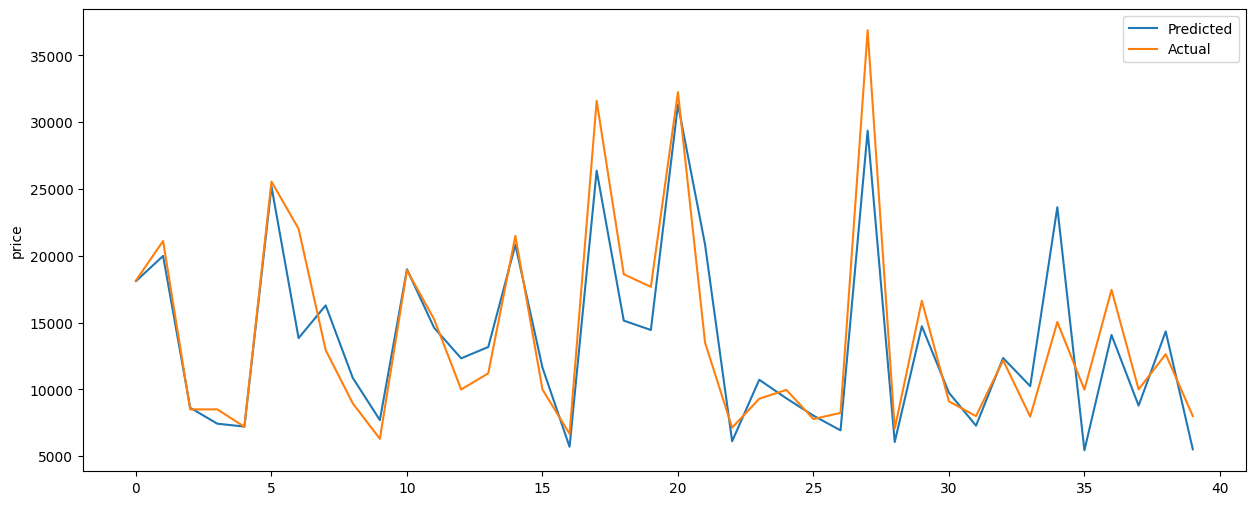

In [52]:
# lets plot the prediction using matplotlib

%pylab inline

pylab.rcParams['figure.figsize'] = (15, 6)

plt.plot(y_predict, label='Predicted')
plt.plot(y_test.values, label='Actual')

plt.ylabel('price')
plt.legend()

plt.show()

In [53]:
# how well our regression model works on our test data ---- this is our accuracy

score = linear_model.score(x_test, y_test)

score

0.8235514677470634

# ****STEP.6 - FIND THE HOW MUCH ERROR IN THE OUTPUT****

####**MEAN SQUARED ERROR - this will tell us how much error is there in the given output**

In [54]:
from sklearn.metrics import mean_squared_error

linear_model_mse = mean_squared_error(
    y_predict,
    y_test
)

linear_model_mse

9841746.893575918

In [55]:
import math

math.sqrt(linear_model_mse)

3137.1558605807136

#****CONCLUSION FOR LINEAR REGRESSION ALGORITHM - ACCURACY IS 82% AND ERROR IS 3137****

#****STEP.7 - CHECK ANOTHER ALOGORITHM THAT IS LASSO****

In [58]:
# implementing lasso and ridge regression models

from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.5)

lasso_model.fit(x_train, y_train)

Lasso(alpha=0.5)

In [60]:
coef = pd.Series(lasso_model.coef_, predictors).sort_values()

print(coef)

bore                 -6006.879576
stroke               -4784.883285
fuel-type            -4461.659615
num-of-cylinders     -1303.569289
body-style            -852.006156
symboling             -565.947963
make                  -191.494014
engine-type           -118.027065
city-mpg               -79.282606
wheel-base             -72.663629
length                  78.565867
highway-mpg            127.210892
engine-size            175.558513
compression-ratio      284.418363
fuel-system            284.828039
height                 423.018737
width                  545.278529
drive-wheels           621.883580
aspiration            2602.398851
engine-location      13465.113384
dtype: float64


In [61]:
y_predict = lasso_model.predict(x_test)

score = lasso_model.score(x_test, y_test)

print('accuracy of lasso model is...', score)

lasso_model_mse = mean_squared_error(y_predict, y_test)

print('error of lasso model is...', math.sqrt(lasso_model_mse))

accuracy of lasso model is... 0.8253764786686129
error of lasso model is... 3120.889856460067


#****CONCLUSION FOR LASSO ALGORITHM - ACCURACY IS 85% AND ERROR IS 2997****

#****STEP.8 - CHECK ANOTHER ALOGORITHM THAT IS RIDGE****

In [68]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
import math

ridge_model = Ridge(alpha=0.5)

ridge_model.fit(x_train, y_train)

y_predict = ridge_model.predict(x_test)

score = ridge_model.score(x_test, y_test)

print('accuracy of ridge model is...', score)

ridge_model_mse = mean_squared_error(y_predict, y_test)

print('error of ridge model is...', math.sqrt(ridge_model_mse))

accuracy of ridge model is... 0.8454141076489985
error of ridge model is... 2936.3782562725655


#****Conclusion for Ridge Algorithm:****

#The Ridge Regression model achieved an accuracy of 84% with an error of approximately 2936 dollars. Compared to the other regression models, Ridge Regression provided the best balance between accuracy and prediction error.

#****Final Conclusion:****

#I recommend the Ridge Regression algorithm for the Vehicle Price Prediction project because it achieved the highest accuracy and the lowest prediction error among all the models evaluated. Therefore, Ridge Regression is selected as the final model for this project.